In [1]:
# Colab에 없는 패키지만 설치합니다 (numpy, pandas, scipy, matplotlib, torch, transformers는 기본 설치).
%pip -q install pyarrow boto3 "transformers>=4.43"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.0/140.0 kB 5.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.1/16.1 MB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 kB 5.2 MB/s eta 0:00:00


# TQP × Temporal Event Graph — 4계층 End-to-End 검증 (AV2 실데이터 + Qwen2.5-1.5B)

이 노트북은 연구의 네 계층이 실제로 연결되어 작동하는지를 한 번에 확인합니다.

| 계층 | 역할 | 연구 분야 | 확인 위치 |
|---|---|---|---|
| Temporal Relation Grounding | 시간 접속사(before/after/while)의 의미와 사건 순서 해석 | NLP 핵심 문제 | 6절 |
| Temporal Query Plan | 자연어를 실행 가능한 관계 구조(JSON)로 변환 | Semantic Parsing | 6절 |
| Temporal Event Graph | 주행 데이터를 사건·관계 그래프로 표현 | Structured Data Representation | 4절 |
| Graph Query Execution | 관계 패턴에 따라 주행 장면 검색 | Information Retrieval | 5절 |
| End-to-end | 자연어 → TQP → 그래프 검색 결과 | 전체 | 7절 |

**실행 방법**
1. 상단 메뉴 **런타임 → 런타임 유형 변경 → T4 GPU**를 선택합니다. GPU가 없어도 동작하지만 LLM 단계가 10분 이상 걸릴 수 있습니다.
2. **런타임 → 모두 실행**을 선택하고, Google Drive 인증 창이 나오면 로그인합니다.

**v0.1 대비 변경 사항**
- 관측 경계에서 잘린 사건을 시작/끝으로 구분하고, 잘린 경계를 어떻게 연장해도 판정이 같으면 확정합니다. v0.1에서 UNCERTAIN으로 버려진 "회전 후 감속" 사례가 이제 양성으로 판정됩니다.
- 그래프 구축 시간은 tracemalloc 없이 측정하고, 메모리는 별도로 측정합니다.
- 질의 시간은 두 실행기 모두 "조건을 만족하는 (트랙, 사건 쌍) 반환"으로 비교합니다.
- 사건 시각은 로그 시작 기준입니다.
- 기본값으로 val 150개 로그 전체를 사용합니다. v0.1에서 Drive에 받은 3개 로그는 재사용됩니다.

**주의**: 사건 검출기는 규칙 기반 파일럿이며 정확도는 3절의 수동 확인으로 측정해야 합니다. LLM 진단 세트는 템플릿 문장 72개입니다. 직접 Python 생성(B2) 비교는 이 노트북에 포함되지 않습니다.

## 1. 설정

In [2]:
from pathlib import Path

# ---- 데이터 ----
DATA_SPLIT = "val"          # 개발·검증용. 최종 평가는 별도 split로 분리
MAX_LOGS = 150              # val 전체 = 150개. 빠른 확인은 20
DOWNLOAD_WORKERS = 16
POSE_TOLERANCE_MS = 15.0

# ---- 그래프 검색 측정 ----
LATENCY_REPEAT = 30         # 질의당 최대 반복 횟수 (질의당 0.5초 시간 제한)

# ---- LLM (Temporal Relation Grounding + TQP) ----
USE_LLM = True
LLM_MODEL_ID = "Qwen/Qwen2.5-1.5B-Instruct"
LLM_BATCH_SIZE = 16

# ---- 검출기 시각 검증 ----
N_TRACKS_TO_PLOT = 12

# ---- 저장 ----
MOUNT_GOOGLE_DRIVE = True
DRIVE_ROOT = "/content/drive/MyDrive"
CACHE_DIR_NAME = "AV2_TEG_Pilot_Data"      # v0.1과 같은 캐시 폴더 (기존 로그 재사용)
RESULTS_DIR_NAME = "AV2_TQP_TEG_Results"
SEED = 0
print("split:", DATA_SPLIT, "| logs:", MAX_LOGS, "| LLM:", LLM_MODEL_ID if USE_LLM else "사용 안 함")

split: val | logs: 150 | LLM: Qwen/Qwen2.5-1.5B-Instruct


## 2. 엔진 설치 및 단위 테스트

`tqp_teg.py`(관계 판정·그래프·실행기·검출기·AV2 로더), `tqp_nl.py`(진단 문장·프롬프트·TQP 파싱·채점), 테스트 파일을 생성합니다.

In [3]:
%%writefile tqp_teg.py
# -*- coding: utf-8 -*-
"""TQP x Temporal Event Graph core engine (v0.2).

Layers implemented here
  - Temporal Query Plan (TQP): strict JSON schema -> Query (no code execution)
  - Temporal Event Graph (TEG): event nodes, HAS_EVENT edges, typed THEN/WHILE edges
  - Query execution: IntervalExecutor (baseline, evaluates intervals at query time)
                     GraphQueryExecutor (looks up precomputed relation edges)
  - AV2 Sensor grounding: annotations.feather + city_SE3_egovehicle.feather per log

Changes from v0.1
  - Boundary clipping is split into clipped_start / clipped_end. A pair is UNCERTAIN
    only when extending the unobserved boundary could change the verdict for the
    queried relation (dense-grid check), instead of whenever any event is clipped.
  - Timing: graph build is timed without tracemalloc; memory is measured separately.
  - Retrieval latency compares "return matching (track, event pair)" for both
    executors, so the graph's precomputation is actually exercised.
  - Event times are relative to the log start (not the track's first observation).
"""
from __future__ import annotations

import re
import time
import tracemalloc
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Dict, FrozenSet, Iterable, List, Optional, Sequence, Tuple

import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
from scipy.spatial.transform import Rotation

VERSION = "0.2.0"
EVENT_TYPES = ("TURN", "DECELERATE", "ACCELERATE", "STOP")
RELATIONS = ("THEN", "WHILE")
LABELS = ("NONE", "THEN", "WHILE", "PARTIAL")
STATUS_ORDER = ("POSITIVE", "UNCERTAIN", "PARTIAL", "NEGATIVE")
VEHICLE_CATEGORIES = {
    "REGULAR_VEHICLE", "LARGE_VEHICLE", "BUS", "BOX_TRUCK",
    "TRUCK", "TRUCK_CAB", "SCHOOL_BUS", "ARTICULATED_BUS",
}
_trapz = getattr(np, "trapezoid", None) or np.trapz


# ---------------------------------------------------------------------------
# Configuration
# ---------------------------------------------------------------------------
@dataclass(frozen=True)
class RelationConfig:
    then_max_gap_s: float = 5.0          # THEN: start(B) - end(A) <= this
    then_overlap_tolerance_s: float = 0.5  # THEN: allows up to 0.5 s overlap
    while_min_overlap_s: float = 0.5     # WHILE/PARTIAL: overlap must exceed this
    while_min_ratio: float = 0.8         # WHILE: overlap / shorter duration >= this
    # Unobserved boundaries are checked on a grid at the 10 Hz sampling resolution.
    # With >=3 unobserved boundaries in one pair the grid is coarsened (rare case).
    clip_grid_step_s: float = 0.1
    clip_grid_max_points: int = 300_000


@dataclass(frozen=True)
class DetectorConfig:
    window: int = 11                 # Savitzky-Golay window at 10 Hz (1.1 s)
    polyorder: int = 2
    max_gap_s: float = 0.25          # split track at missing frames
    min_displacement_m: float = 3.0
    decel_threshold: float = -1.0    # m/s^2
    accel_threshold: float = 1.0
    min_speed_change: float = 1.5    # m/s over the event
    min_accel_duration_s: float = 0.5
    stop_speed: float = 0.5          # m/s
    min_stop_duration_s: float = 1.0
    turn_rate_deg_s: float = 5.0
    min_turn_deg: float = 45.0
    min_turn_travel_m: float = 5.0
    min_turn_speed: float = 1.0


DEFAULT_REL = RelationConfig()
DEFAULT_DET = DetectorConfig()


# ---------------------------------------------------------------------------
# Data model
# ---------------------------------------------------------------------------
@dataclass(frozen=True)
class Event:
    event_id: str
    log_id: str
    track_id: str
    type: str
    start: float
    end: float
    clipped_start: bool = False   # true start may be earlier (observation began mid-event)
    clipped_end: bool = False     # true end may be later (observation ended mid-event)

    def __post_init__(self) -> None:
        if self.type not in EVENT_TYPES:
            raise ValueError(f"Unknown event type: {self.type}")
        if not (np.isfinite(self.start) and np.isfinite(self.end) and self.end > self.start):
            raise ValueError("Event must have a finite positive duration")

    @property
    def track_key(self) -> Tuple[str, str]:
        return (self.log_id, self.track_id)

    @property
    def clipped(self) -> bool:
        return self.clipped_start or self.clipped_end


@dataclass(frozen=True)
class Query:
    first: str      # temporally first argument (for WHILE: order irrelevant)
    relation: str
    second: str

    def __post_init__(self) -> None:
        if self.first not in EVENT_TYPES or self.second not in EVENT_TYPES:
            raise ValueError("Unsupported event type")
        if self.relation not in RELATIONS:
            raise ValueError("Unsupported relation")

    def __str__(self) -> str:
        return f"{self.first} {self.relation} {self.second}"

    def semantic_key(self) -> tuple:
        if self.relation == "WHILE":
            return ("WHILE",) + tuple(sorted((self.first, self.second)))
        return ("THEN", self.first, self.second)

    def to_tqp(self) -> dict:
        return {"events": {"e1": self.first, "e2": self.second},
                "relation": {"op": self.relation, "args": ["e1", "e2"]}}


@dataclass(frozen=True, order=True)
class Match:
    log_id: str
    track_id: str
    first_event_id: str
    first_type: str
    first_start: float
    first_end: float
    second_event_id: str
    second_type: str
    second_start: float
    second_end: float

    @staticmethod
    def of(a: Event, b: Event) -> "Match":
        return Match(a.log_id, a.track_id, a.event_id, a.type, a.start, a.end,
                     b.event_id, b.type, b.start, b.end)


def parse_tqp(plan: dict) -> Query:
    """Validate a TQP dict and return the temporally ordered Query.

    Schema: {"events": {"e1": TYPE, "e2": TYPE},
             "relation": {"op": "THEN"|"WHILE", "args": [slot, slot]}}
    args lists the slots in temporal order (args[0] happens first for THEN).
    """
    if not isinstance(plan, dict) or set(plan) != {"events", "relation"}:
        raise ValueError("TQP must have exactly the keys 'events' and 'relation'")
    events, relation = plan["events"], plan["relation"]
    if not isinstance(events, dict) or set(events) != {"e1", "e2"}:
        raise ValueError("Expected event slots e1 and e2")
    for slot, typ in events.items():
        if typ not in EVENT_TYPES:
            raise ValueError(f"Unsupported event type in {slot}: {typ!r}")
    if not isinstance(relation, dict) or set(relation) != {"op", "args"}:
        raise ValueError("Expected relation keys op and args")
    if relation["op"] not in RELATIONS:
        raise ValueError(f"Unsupported relation op: {relation['op']!r}")
    args = relation["args"]
    if not isinstance(args, list) or sorted(args) != ["e1", "e2"]:
        raise ValueError("Relation args must contain e1 and e2 exactly once")
    return Query(events[args[0]], relation["op"], events[args[1]])


# ---------------------------------------------------------------------------
# Interval relation semantics (shared by both executors)
# ---------------------------------------------------------------------------
def _label_codes(sa, ea, sb, eb, cfg: RelationConfig):
    """Vectorised relation label for ordered pair (A, B). 0 NONE 1 THEN 2 WHILE 3 PARTIAL."""
    ov = np.maximum(0.0, np.minimum(ea, eb) - np.maximum(sa, sb))
    shorter = np.minimum(ea - sa, eb - sb)
    overlapping = ov > cfg.while_min_overlap_s
    ratio = ov / np.where(shorter > 0, shorter, 1.0)
    is_while = overlapping & (ratio >= cfg.while_min_ratio - 1e-12)
    is_partial = overlapping & ~is_while
    gap = sb - ea
    is_then = ((~overlapping) & (sa < sb)
               & (gap >= -cfg.then_overlap_tolerance_s - 1e-12)
               & (gap <= cfg.then_max_gap_s + 1e-12))
    code = np.where(is_then, 1, 0)
    code = np.where(is_while, 2, code)
    code = np.where(is_partial, 3, code)
    return code


def possible_relations(a: Event, b: Event, cfg: RelationConfig = DEFAULT_REL) -> FrozenSet[str]:
    """Set of labels the ordered pair (a, b) can take over all completions of
    clipped (unobserved) boundaries. Unclipped pairs return a singleton."""
    if a.event_id == b.event_id or a.track_key != b.track_key:
        return frozenset({"NONE"})
    free = (a.clipped_start, a.clipped_end, b.clipped_start, b.clipped_end)
    k = sum(free)
    if k == 0:
        code = int(_label_codes(a.start, a.end, b.start, b.end, cfg))
        return frozenset({LABELS[code]})
    # Beyond this extension every comparison in _label_codes is saturated.
    horizon = (max(a.end, b.end) - min(a.start, b.start)
               + cfg.then_max_gap_s + cfg.then_overlap_tolerance_s + 1.0)
    n = int(np.ceil(horizon / cfg.clip_grid_step_s)) + 1
    n = max(2, min(n, int(cfg.clip_grid_max_points ** (1.0 / k))))
    ext = np.linspace(0.0, horizon, n)
    axis_i = 0

    def axis(base: float, sign: float, is_free: bool):
        nonlocal axis_i
        if not is_free:
            return np.float64(base)
        shape = [1] * k
        shape[axis_i] = n
        axis_i += 1
        return base + sign * ext.reshape(shape)

    sa = axis(a.start, -1.0, a.clipped_start)
    ea = axis(a.end, +1.0, a.clipped_end)
    sb = axis(b.start, -1.0, b.clipped_start)
    eb = axis(b.end, +1.0, b.clipped_end)
    codes = np.unique(_label_codes(sa, ea, sb, eb, cfg))
    return frozenset(LABELS[int(c)] for c in codes)


def pair_status(possible: FrozenSet[str], relation: str) -> str:
    """POSITIVE: relation holds for every completion. UNCERTAIN: holds for some.
    PARTIAL: insufficient overlap (ambiguous for both operators). Else NEGATIVE."""
    if possible == frozenset({relation}):
        return "POSITIVE"
    if relation in possible:
        return "UNCERTAIN"
    if "PARTIAL" in possible:
        return "PARTIAL"
    return "NEGATIVE"


def stronger(s1: str, s2: str) -> str:
    return s1 if STATUS_ORDER.index(s1) <= STATUS_ORDER.index(s2) else s2


# ---------------------------------------------------------------------------
# Executor 1: interval baseline
# ---------------------------------------------------------------------------
class IntervalExecutor:
    """Evaluates interval pairs at query time; only events are grouped by track/type."""

    def __init__(self, events: Sequence[Event], track_universe: Iterable[Tuple[str, str]] = (),
                 cfg: RelationConfig = DEFAULT_REL):
        self.cfg = cfg
        grouped: Dict[Tuple[str, str], Dict[str, List[Event]]] = defaultdict(lambda: defaultdict(list))
        for e in events:
            grouped[e.track_key][e.type].append(e)
        self.by_track = {k: dict(v) for k, v in grouped.items()}
        self.keys = set(map(tuple, track_universe)) | set(self.by_track)

    def _pairs(self, q: Query):
        for key, types in self.by_track.items():
            for a in types.get(q.first, ()):
                for b in types.get(q.second, ()):
                    if a.event_id != b.event_id:
                        yield key, a, b

    def retrieve(self, q: Query) -> List[Match]:
        return sorted(Match.of(a, b) for _, a, b in self._pairs(q)
                      if pair_status(possible_relations(a, b, self.cfg), q.relation) == "POSITIVE")

    def statuses(self, q: Query) -> Dict[Tuple[str, str], str]:
        out = {k: "NEGATIVE" for k in self.keys}
        for key, a, b in self._pairs(q):
            out[key] = stronger(out[key], pair_status(possible_relations(a, b, self.cfg), q.relation))
        return out


# ---------------------------------------------------------------------------
# Temporal Event Graph + executor 2
# ---------------------------------------------------------------------------
class TemporalEventGraph:
    """Nodes: tracks and events. Edges: HAS_EVENT (track->event) and typed relation
    edges THEN/WHILE (event->event) that hold for every boundary completion.
    Ambiguous pairs are indexed separately so they are never returned as matches
    and never counted as negatives."""

    def __init__(self, events: Sequence[Event], track_universe: Iterable[Tuple[str, str]] = (),
                 cfg: RelationConfig = DEFAULT_REL):
        self.cfg = cfg
        self.event_nodes: Dict[str, Event] = {}
        self.has_event: Dict[Tuple[str, str], List[str]] = defaultdict(list)
        for e in events:
            if e.event_id in self.event_nodes:
                raise ValueError(f"Duplicate event_id {e.event_id}")
            self.event_nodes[e.event_id] = e
            self.has_event[e.track_key].append(e.event_id)
        self.track_nodes = set(map(tuple, track_universe)) | set(self.has_event)
        self.relation_edges: List[Tuple[str, str, str]] = []
        self.edge_index: Dict[tuple, List[Tuple[str, str]]] = defaultdict(list)
        self.ambiguous_index: Dict[tuple, Dict[Tuple[str, str], str]] = defaultdict(dict)
        self.pairs_evaluated = 0
        self.clip_aware_pairs = 0
        for key, ids in self.has_event.items():
            evs = [self.event_nodes[i] for i in ids]
            for a in evs:
                for b in evs:
                    if a.event_id == b.event_id:
                        continue
                    self.pairs_evaluated += 1
                    self.clip_aware_pairs += int(a.clipped or b.clipped)
                    poss = possible_relations(a, b, cfg)
                    for rel in RELATIONS:
                        st = pair_status(poss, rel)
                        index_key = (rel, a.type, b.type)
                        if st == "POSITIVE":
                            self.relation_edges.append((a.event_id, rel, b.event_id))
                            self.edge_index[index_key].append((a.event_id, b.event_id))
                        elif st in ("UNCERTAIN", "PARTIAL"):
                            bucket = self.ambiguous_index[index_key]
                            bucket[key] = stronger(bucket.get(key, "NEGATIVE"), st)
        self.edge_index = dict(self.edge_index)
        self.ambiguous_index = dict(self.ambiguous_index)

    def summary(self) -> dict:
        return {
            "track_nodes": len(self.track_nodes),
            "event_nodes": len(self.event_nodes),
            "has_event_edges": sum(len(v) for v in self.has_event.values()),
            "relation_edges": len(self.relation_edges),
            "relation_edges_by_type": dict(Counter(r for _, r, _ in self.relation_edges)),
            "relation_edges_by_pattern": {f"{k[1]} {k[0]} {k[2]}": len(v)
                                          for k, v in sorted(self.edge_index.items())},
            "ordered_event_pairs_evaluated": self.pairs_evaluated,
            "pairs_with_clipped_boundary": self.clip_aware_pairs,
            "note": "WHILE is symmetric, so each WHILE relation is stored as two directed edges.",
        }

    def edges_frame(self) -> pd.DataFrame:
        rows = []
        for s, r, d in self.relation_edges:
            a, b = self.event_nodes[s], self.event_nodes[d]
            rows.append({"source_event_id": s, "relation": r, "target_event_id": d,
                         "log_id": a.log_id, "track_id": a.track_id,
                         "source_type": a.type, "target_type": b.type,
                         "source_start": a.start, "source_end": a.end,
                         "target_start": b.start, "target_end": b.end})
        return pd.DataFrame(rows, columns=["source_event_id", "relation", "target_event_id", "log_id",
                                           "track_id", "source_type", "target_type", "source_start",
                                           "source_end", "target_start", "target_end"])


class GraphQueryExecutor:
    """Translates a TQP Query into a typed edge-pattern lookup on the graph."""

    def __init__(self, graph: TemporalEventGraph):
        self.g = graph

    @staticmethod
    def pattern(q: Query) -> str:
        return f"(:Event {{type:'{q.first}'}})-[:{q.relation}]->(:Event {{type:'{q.second}'}})"

    def retrieve(self, q: Query) -> List[Match]:
        pairs = self.g.edge_index.get((q.relation, q.first, q.second), ())
        nodes = self.g.event_nodes
        return sorted(Match.of(nodes[s], nodes[d]) for s, d in pairs)

    def statuses(self, q: Query) -> Dict[Tuple[str, str], str]:
        idx = (q.relation, q.first, q.second)
        out = {k: "NEGATIVE" for k in self.g.track_nodes}
        out.update(self.g.ambiguous_index.get(idx, {}))
        for s, _ in self.g.edge_index.get(idx, ()):
            out[self.g.event_nodes[s].track_key] = "POSITIVE"
        return out


def all_queries() -> List[Query]:
    return [Query(x, r, y) for x in EVENT_TYPES for r in RELATIONS for y in EVENT_TYPES]


def verify_and_benchmark(events: Sequence[Event], universe: Iterable[Tuple[str, str]],
                         queries: Sequence[Query], cfg: RelationConfig = DEFAULT_REL, *,
                         repeat: int = 30, build_repeats: int = 3,
                         time_budget_s: float = 0.5) -> Tuple[dict, TemporalEventGraph]:
    universe = set(map(tuple, universe))
    build_ms, prep_ms = [], []
    graph = None
    for _ in range(build_repeats):
        t0 = time.perf_counter()
        graph = TemporalEventGraph(events, universe, cfg)
        build_ms.append((time.perf_counter() - t0) * 1000)
        t0 = time.perf_counter()
        interval = IntervalExecutor(events, universe, cfg)
        prep_ms.append((time.perf_counter() - t0) * 1000)
    tracemalloc.start()
    probe = TemporalEventGraph(events, universe, cfg)
    retained, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    del probe
    gexec = GraphQueryExecutor(graph)

    per_query = []
    for q in queries:
        si, sg = interval.statuses(q), gexec.statuses(q)
        ri, rg = interval.retrieve(q), gexec.retrieve(q)
        mism = [[*k, si[k], sg.get(k)] for k in si if si[k] != sg.get(k)]
        per_query.append({
            "query": str(q), "graph_pattern": gexec.pattern(q),
            "status_equal": si == sg, "retrieval_equal": ri == rg,
            "matches": len(rg), "positive_tracks": sum(v == "POSITIVE" for v in sg.values()),
            "uncertain_tracks": sum(v == "UNCERTAIN" for v in sg.values()),
            "partial_tracks": sum(v == "PARTIAL" for v in sg.values()),
            "negative_tracks": sum(v == "NEGATIVE" for v in sg.values()),
            "mismatches": mism[:10],
        })

    def latency(fn) -> List[float]:
        """Mean ms per call; at most `repeat` calls or ~time_budget_s per query (>=1 call)."""
        out = []
        for q in queries:
            n, t0 = 0, time.perf_counter()
            while n < repeat:
                fn(q)
                n += 1
                if time.perf_counter() - t0 > time_budget_s:
                    break
            out.append((time.perf_counter() - t0) * 1000 / n)
        return out

    lat_i, lat_g = latency(interval.retrieve), latency(gexec.retrieve)
    for row, li, lg in zip(per_query, lat_i, lat_g):
        row["interval_ms"], row["graph_ms"] = round(li, 5), round(lg, 5)
    build = float(np.median(build_ms))
    saved = float(np.mean(lat_i) - np.mean(lat_g))
    report = {
        "version": VERSION,
        "relation_config": asdict(cfg),
        "graph": graph.summary(),
        "graph_build_ms_median": round(build, 3),
        "interval_prep_ms_median": round(float(np.median(prep_ms)), 3),
        "graph_retained_memory_kib": round(retained / 1024, 1),
        "graph_build_peak_memory_kib": round(peak / 1024, 1),
        "retrieval_latency_interval_ms_mean": round(float(np.mean(lat_i)), 5),
        "retrieval_latency_graph_ms_mean": round(float(np.mean(lat_g)), 5),
        "break_even_query_count": (int(np.ceil(build / saved)) if saved > 0 else None),
        "latency_repeat_max": repeat,
        "latency_time_budget_s_per_query": time_budget_s,
        "query_count": len(queries),
        "all_status_equal": all(r["status_equal"] for r in per_query),
        "all_retrieval_equal": all(r["retrieval_equal"] for r in per_query),
        "per_query": per_query,
    }
    return report, graph


# ---------------------------------------------------------------------------
# Event detection from trajectories
# ---------------------------------------------------------------------------
def contiguous_runs(mask: np.ndarray) -> List[Tuple[int, int]]:
    padded = np.r_[False, np.asarray(mask, dtype=bool), False].astype(int)
    d = np.diff(padded)
    return list(zip(np.flatnonzero(d == 1).tolist(), np.flatnonzero(d == -1).tolist()))


def extract_events(t, x, y, log_id: str, track_id: str,
                   dcfg: DetectorConfig = DEFAULT_DET) -> Tuple[List[Event], List[dict]]:
    """Rule-based pilot detector for ~10 Hz trajectories (times in seconds, log-relative).
    Returns events and per-segment signals for visual verification."""
    t, x, y = (np.asarray(v, float) for v in (t, x, y))
    events: List[Event] = []
    segments: List[dict] = []
    if len(t) < dcfg.window:
        return events, segments
    order = np.argsort(t)
    t, x, y = t[order], x[order], y[order]
    cuts = np.r_[0, np.flatnonzero(np.diff(t) > dcfg.max_gap_s) + 1, len(t)]
    for lo, hi in zip(cuts[:-1], cuts[1:]):
        tt, xx, yy = t[lo:hi], x[lo:hi], y[lo:hi]
        if len(tt) < dcfg.window or np.any(np.diff(tt) <= 0):
            continue
        dt = float(np.median(np.diff(tt)))
        if not 0.075 <= dt <= 0.125:
            continue
        if np.max(np.hypot(xx - xx[0], yy - yy[0])) < dcfg.min_displacement_m:
            continue
        w, p = dcfg.window, dcfg.polyorder
        vx = savgol_filter(xx, w, p, deriv=1, delta=dt)
        vy = savgol_filter(yy, w, p, deriv=1, delta=dt)
        speed = np.hypot(vx, vy)
        accel = savgol_filter(speed, w, p, deriv=1, delta=dt)
        heading = np.unwrap(np.arctan2(vy, vx))
        yaw_rate = savgol_filter(heading, w, p, deriv=1, delta=dt)
        travel = np.r_[0.0, np.cumsum(np.hypot(np.diff(xx), np.diff(yy)))]
        segments.append({"t": tt, "x": xx, "y": yy, "speed": speed,
                         "accel": accel, "yaw_rate_deg_s": np.rad2deg(yaw_rate)})
        rate = np.deg2rad(dcfg.turn_rate_deg_s)
        candidates = [("DECELERATE", accel <= dcfg.decel_threshold),
                      ("ACCELERATE", accel >= dcfg.accel_threshold),
                      ("STOP", speed < dcfg.stop_speed),
                      ("TURN", yaw_rate >= rate),
                      ("TURN", yaw_rate <= -rate)]
        for kind, mask in candidates:
            for a, b in contiguous_runs(mask):
                duration = (b - a) * dt
                if kind == "STOP":
                    valid = duration >= dcfg.min_stop_duration_s - 1e-9
                elif kind in ("DECELERATE", "ACCELERATE"):
                    dv = speed[b - 1] - speed[a]
                    ok_dv = dv <= -dcfg.min_speed_change if kind == "DECELERATE" else dv >= dcfg.min_speed_change
                    valid = duration >= dcfg.min_accel_duration_s - 1e-9 and ok_dv
                else:
                    angle = abs(_trapz(yaw_rate[a:b], dx=dt))
                    valid = (angle >= np.deg2rad(dcfg.min_turn_deg)
                             and travel[b - 1] - travel[a] >= dcfg.min_turn_travel_m
                             and float(np.median(speed[a:b])) >= dcfg.min_turn_speed)
                if valid:
                    events.append(Event(f"{log_id}:{track_id}:{len(events)}", log_id, track_id, kind,
                                        float(tt[a]), float(tt[b - 1] + dt),
                                        clipped_start=(a == 0), clipped_end=(b == len(tt))))
    return events, segments


# ---------------------------------------------------------------------------
# AV2 Sensor log loading
# ---------------------------------------------------------------------------
ANNOTATION = "annotations.feather"
POSE = "city_SE3_egovehicle.feather"
SENSOR_COLUMNS = {
    ANNOTATION: ["timestamp_ns", "track_uuid", "category", "tx_m", "ty_m", "tz_m"],
    POSE: ["timestamp_ns", "qw", "qx", "qy", "qz", "tx_m", "ty_m", "tz_m"],
}
UUID_RE = re.compile(r"^[0-9a-f]{8}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{4}-[0-9a-f]{12}$", re.I)


def load_av2_log(folder: Path, *, pose_tolerance_ms: float = 15.0,
                 dcfg: DetectorConfig = DEFAULT_DET):
    """Annotation cuboid centres (ego frame) -> city frame via nearest ego pose,
    then rule-based event detection. Time origin = first annotation of the log."""
    folder = Path(folder)
    ann = pd.read_feather(folder / ANNOTATION, columns=SENSOR_COLUMNS[ANNOTATION])
    pose = pd.read_feather(folder / POSE, columns=SENSOR_COLUMNS[POSE])
    t0_ns = int(ann.timestamp_ns.min())
    log_duration_s = (int(ann.timestamp_ns.max()) - t0_ns) / 1e9
    ann = ann[ann.category.isin(VEHICLE_CATEGORIES)].copy()
    ann = ann.sort_values(["timestamp_ns", "track_uuid"]).drop_duplicates(["track_uuid", "timestamp_ns"])
    pose = pose.sort_values("timestamp_ns").drop_duplicates("timestamp_ns")
    pose = pose.rename(columns={c: f"pose_{c}" for c in pose.columns})
    joined = pd.merge_asof(ann.sort_values("timestamp_ns"), pose,
                           left_on="timestamp_ns", right_on="pose_timestamp_ns",
                           direction="nearest", tolerance=int(pose_tolerance_ms * 1e6))
    unmatched = int(joined.pose_timestamp_ns.isna().sum())
    joined = joined.dropna(subset=["pose_timestamp_ns"]).copy()
    if len(ann) and unmatched / len(ann) > 0.05:
        raise ValueError(f"{folder.name}: >5% annotations lack an ego pose within tolerance")
    log_id = folder.name
    events: List[Event] = []
    universe = set()
    signals: Dict[Tuple[str, str], List[dict]] = {}
    max_dt_ms = 0.0
    if len(joined):
        ego = joined[["tx_m", "ty_m", "tz_m"]].to_numpy(float)
        quat = joined[["pose_qx", "pose_qy", "pose_qz", "pose_qw"]].to_numpy(float)
        trans = joined[["pose_tx_m", "pose_ty_m", "pose_tz_m"]].to_numpy(float)
        city = Rotation.from_quat(quat).apply(ego) + trans
        joined["cx"], joined["cy"] = city[:, 0], city[:, 1]
        max_dt_ms = float(np.max(np.abs(joined.timestamp_ns - joined.pose_timestamp_ns)) / 1e6)
        for track_id, df in joined.groupby("track_uuid", sort=True):
            tt = (df.timestamp_ns.to_numpy(np.int64) - t0_ns) / 1e9
            xx, yy = df.cx.to_numpy(), df.cy.to_numpy()
            if len(tt) < dcfg.window or np.ptp(tt) < 1.0:
                continue
            if np.max(np.hypot(xx - xx[0], yy - yy[0])) < dcfg.min_displacement_m:
                continue
            key = (log_id, str(track_id))
            evs, segs = extract_events(tt, xx, yy, log_id, str(track_id), dcfg)
            if not segs:
                continue
            universe.add(key)
            signals[key] = segs
            events.extend(evs)
    info = {"log_id": log_id, "log_duration_s": round(log_duration_s, 2),
            "vehicle_annotation_rows": int(len(ann)),
            "pose_match_rate": round(1 - unmatched / max(len(ann), 1), 6),
            "max_pose_time_difference_ms": round(max_dt_ms, 3),
            "vehicle_tracks": int(ann.track_uuid.nunique()),
            "moving_tracks_evaluated": len(universe),
            "events": len(events),
            "events_by_type": dict(Counter(e.type for e in events))}
    return events, info, universe, signals


def valid_pair(folder: Path) -> bool:
    import pyarrow.feather as feather
    try:
        for name, cols in SENSOR_COLUMNS.items():
            p = Path(folder) / name
            if not p.is_file() or p.stat().st_size < 128:
                return False
            tab = feather.read_table(str(p), columns=cols)
            if tab.num_rows == 0:
                return False
        return True
    except Exception:
        return False


def _s3_client():
    import boto3
    from botocore import UNSIGNED
    from botocore.config import Config
    return boto3.client("s3", config=Config(signature_version=UNSIGNED, region_name="us-east-1",
                                            connect_timeout=15, read_timeout=90,
                                            retries={"max_attempts": 3},
                                            max_pool_connections=32))


def list_s3_logs(split: str) -> List[str]:
    client = _s3_client()
    prefix = f"datasets/av2/sensor/{split}/"
    ids, token = [], None
    while True:
        kw = dict(Bucket="argoverse", Prefix=prefix, Delimiter="/", MaxKeys=1000)
        if token:
            kw["ContinuationToken"] = token
        resp = client.list_objects_v2(**kw)
        for cp in resp.get("CommonPrefixes", []):
            name = cp["Prefix"].rstrip("/").split("/")[-1]
            if UUID_RE.match(name):
                ids.append(name)
        token = resp.get("NextContinuationToken")
        if not token:
            break
    return sorted(set(ids))


def ensure_av2_logs(cache_root: Path, split: str = "val", max_logs: int = 150,
                    workers: int = 16, log_ids: Optional[Sequence[str]] = None):
    """Reuse cached log folders; download only the two Feather files per missing log
    from the official public AV2 bucket. Never falls back to synthetic data."""
    cache_dir = Path(cache_root) / "s3" / split
    cache_dir.mkdir(parents=True, exist_ok=True)
    note = None
    if log_ids:
        ids = list(log_ids)
    else:
        try:
            ids = list_s3_logs(split)
        except Exception as exc:  # offline: use whatever valid cache exists
            note = f"S3 listing failed ({type(exc).__name__}: {exc}); using cache only"
            ids = sorted(p.name for p in cache_dir.iterdir() if p.is_dir() and valid_pair(p))
    ids = ids[:max_logs]
    client = _s3_client()

    def fetch(log_id: str):
        folder = cache_dir / log_id
        if valid_pair(folder):
            return log_id, folder, "cache", None
        folder.mkdir(parents=True, exist_ok=True)
        try:
            for name in (ANNOTATION, POSE):
                client.download_file("argoverse", f"datasets/av2/sensor/{split}/{log_id}/{name}",
                                     str(folder / name))
            return (log_id, folder, "s3", None) if valid_pair(folder) else (log_id, None, "invalid", "bad files")
        except Exception as exc:
            return log_id, None, "error", f"{type(exc).__name__}: {exc}"

    results = []
    with ThreadPoolExecutor(max_workers=workers) as pool:
        for r in pool.map(fetch, ids):
            results.append(r)
    folders = [f for _, f, _, _ in results if f is not None]
    if not folders:
        raise RuntimeError("No valid AV2 Sensor log pairs available (network and cache both failed).")
    info = {"split": split, "requested": len(ids), "ready": len(folders),
            "from_cache": sum(r[2] == "cache" for r in results),
            "downloaded": sum(r[2] == "s3" for r in results),
            "failed": [(r[0], r[3]) for r in results if r[1] is None],
            "note": note}
    return sorted(folders), info


# ---------------------------------------------------------------------------
# Visual verification helpers
# ---------------------------------------------------------------------------
TYPE_COLORS = {"TURN": "#1f77b4", "DECELERATE": "#d62728", "ACCELERATE": "#2ca02c", "STOP": "#7f7f7f"}


def plot_track(key, events: Sequence[Event], segments: Sequence[dict], ax_row, title_extra: str = ""):
    ax_xy, ax_v, ax_w = ax_row
    for seg in segments:
        ax_xy.plot(seg["x"], seg["y"], color="#bbbbbb", lw=1.5)
        ax_v.plot(seg["t"], seg["speed"], color="black", lw=1)
        ax_w.plot(seg["t"], seg["yaw_rate_deg_s"], color="black", lw=1)
        ax_xy.plot(seg["x"][0], seg["y"][0], "o", color="black", ms=4)
    for e in events:
        c = TYPE_COLORS[e.type]
        target = ax_w if e.type == "TURN" else ax_v
        target.axvspan(e.start, e.end, color=c, alpha=0.25)
        for seg in segments:
            m = (seg["t"] >= e.start) & (seg["t"] < e.end)
            if m.any():
                ax_xy.plot(seg["x"][m], seg["y"][m], color=c, lw=3)
    ax_xy.set_aspect("equal", adjustable="datalim")
    ax_xy.set_title(f"{key[0][:8]} / {key[1][:8]} {title_extra}", fontsize=9)
    ax_v.set_ylabel("speed (m/s)")
    ax_w.set_ylabel("yaw rate (deg/s)")
    ax_v.set_xlabel("time since log start (s)")
    ax_w.set_xlabel("time since log start (s)")
    labels = ", ".join(f"{e.type}[{e.start:.1f}-{e.end:.1f}{'*' if e.clipped else ''}]" for e in events)
    ax_v.set_title(labels, fontsize=7)

Writing tqp_teg.py


In [4]:
%%writefile tqp_nl.py
# -*- coding: utf-8 -*-
"""Temporal Relation Grounding + TQP semantic parsing with a small LLM.

- build_diagnostic_set(): templated English sentences with gold TQPs, covering
  before / after / and-then / while / as, in surface-order congruent and
  incongruent forms.
- build_messages(): instruction + few-shot prompt (few-shot sentences are not
  part of the evaluation set).
- parse_prediction(): extract the first JSON object and validate it with the
  strict TQP schema (no code is executed).
- score(): relation / event / direction / exact-plan correctness.
"""
from __future__ import annotations

import json
import time
from typing import List, Optional, Sequence, Tuple

import pandas as pd

from tqp_teg import EVENT_TYPES, Query, parse_tqp

PHRASES = {
    "DECELERATE": {"fin": "slows down", "ger": "slowing down"},
    "TURN": {"fin": "turns", "ger": "turning"},
    "ACCELERATE": {"fin": "speeds up", "ger": "speeding up"},
    "STOP": {"fin": "stops", "ger": "stopping"},
}

# (template id, pattern, relation, temporal order of mentioned events A/B, surface condition)
# A = first-mentioned event, B = second-mentioned event.
THEN_TEMPLATES = [
    ("before", "A vehicle {A_fin} before {B_ger}.", ("A", "B"), "congruent"),
    ("after", "A vehicle {A_fin} after {B_ger}.", ("B", "A"), "incongruent"),
    ("before_fronted", "Before {A_ger}, a vehicle {B_fin}.", ("B", "A"), "incongruent"),
    ("after_fronted", "After {A_ger}, a vehicle {B_fin}.", ("A", "B"), "congruent"),
    ("and_then", "A vehicle {A_fin} and then {B_fin}.", ("A", "B"), "congruent"),
]
WHILE_TEMPLATES = [
    ("while", "A vehicle {A_fin} while {B_ger}."),
    ("while_fronted", "While {A_ger}, a vehicle {B_fin}."),
    ("as", "A vehicle {A_fin} as it {B_fin}."),
]
# Physically plausible simultaneous pairs only.
WHILE_PAIRS = [("DECELERATE", "TURN"), ("TURN", "DECELERATE"),
               ("ACCELERATE", "TURN"), ("TURN", "ACCELERATE")]

SYSTEM_PROMPT = """You convert a sentence describing a vehicle's behaviour into a Temporal Query Plan (TQP) in JSON.

Event types (use these exact strings):
- TURN: the vehicle turns / changes heading
- DECELERATE: the vehicle slows down / brakes
- ACCELERATE: the vehicle speeds up
- STOP: the vehicle stops / comes to a stop

Rules:
1. "e1" is the event mentioned FIRST in the sentence, "e2" the event mentioned SECOND.
2. relation "op" is "THEN" if one event happens after the other, "WHILE" if they happen at the same time.
3. relation "args" lists the slots in the order the events ACTUALLY HAPPEN in time (earlier event first). For WHILE use ["e1", "e2"].
4. Output only the JSON object and nothing else."""

FEW_SHOT = [
    ("A vehicle turns, and afterwards it speeds up.",
     {"events": {"e1": "TURN", "e2": "ACCELERATE"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}}),
    ("A vehicle comes to a stop once it has finished slowing down.",
     {"events": {"e1": "STOP", "e2": "DECELERATE"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}),
    ("A vehicle slows down during its turn.",
     {"events": {"e1": "DECELERATE", "e2": "TURN"}, "relation": {"op": "WHILE", "args": ["e1", "e2"]}}),
]


def _fill(pattern: str, a: str, b: str) -> str:
    return pattern.format(A_fin=PHRASES[a]["fin"], A_ger=PHRASES[a]["ger"],
                          B_fin=PHRASES[b]["fin"], B_ger=PHRASES[b]["ger"])


def gold_tqp(a: str, b: str, relation: str, order: Tuple[str, str]) -> dict:
    slot = {"A": "e1", "B": "e2"}
    return {"events": {"e1": a, "e2": b},
            "relation": {"op": relation, "args": [slot[order[0]], slot[order[1]]]}}


def build_diagnostic_set() -> pd.DataFrame:
    rows = []
    for tid, pattern, order, cond in THEN_TEMPLATES:
        for a in EVENT_TYPES:
            for b in EVENT_TYPES:
                if a == b:
                    continue
                plan = gold_tqp(a, b, "THEN", order)
                q = parse_tqp(plan)
                rows.append({"template": tid, "connective": tid.split("_")[0],
                             "condition": cond, "sentence": _fill(pattern, a, b),
                             "gold_tqp": json.dumps(plan), "gold_first": q.first,
                             "gold_relation": q.relation, "gold_second": q.second})
    for tid, pattern in WHILE_TEMPLATES:
        for a, b in WHILE_PAIRS:
            plan = gold_tqp(a, b, "WHILE", ("A", "B"))
            q = parse_tqp(plan)
            rows.append({"template": tid, "connective": tid.split("_")[0],
                         "condition": "simultaneous", "sentence": _fill(pattern, a, b),
                         "gold_tqp": json.dumps(plan), "gold_first": q.first,
                         "gold_relation": q.relation, "gold_second": q.second})
    df = pd.DataFrame(rows)
    few = {s for s, _ in FEW_SHOT}
    assert not few & set(df.sentence), "few-shot sentences leaked into evaluation set"
    return df.reset_index(drop=True)


def build_messages(sentence: str) -> List[dict]:
    msgs = [{"role": "system", "content": SYSTEM_PROMPT}]
    for s, plan in FEW_SHOT:
        msgs.append({"role": "user", "content": s})
        msgs.append({"role": "assistant", "content": json.dumps(plan)})
    msgs.append({"role": "user", "content": sentence})
    return msgs


def extract_json(text: str) -> dict:
    """Return the first balanced {...} object in text."""
    start = text.find("{")
    if start < 0:
        raise ValueError("no JSON object in output")
    depth, in_str, esc = 0, False, False
    for i in range(start, len(text)):
        ch = text[i]
        if in_str:
            if esc:
                esc = False
            elif ch == "\\":
                esc = True
            elif ch == '"':
                in_str = False
            continue
        if ch == '"':
            in_str = True
        elif ch == "{":
            depth += 1
        elif ch == "}":
            depth -= 1
            if depth == 0:
                return json.loads(text[start:i + 1])
    raise ValueError("unbalanced JSON object in output")


def parse_prediction(text: str) -> Tuple[Optional[Query], Optional[dict], Optional[str]]:
    try:
        plan = extract_json(text)
    except Exception as exc:
        return None, None, f"json: {exc}"
    try:
        return parse_tqp(plan), plan, None
    except Exception as exc:
        return None, plan, f"schema: {exc}"


def score(gold: Query, pred: Optional[Query]) -> dict:
    if pred is None:
        return {"valid": False, "relation_correct": False, "events_correct": False,
                "direction_correct": None if gold.relation == "WHILE" else False, "exact": False}
    events_ok = sorted((pred.first, pred.second)) == sorted((gold.first, gold.second))
    rel_ok = pred.relation == gold.relation
    direction = None
    if gold.relation == "THEN":
        direction = bool(rel_ok and events_ok and pred.first == gold.first and pred.second == gold.second)
    return {"valid": True, "relation_correct": rel_ok, "events_correct": events_ok,
            "direction_correct": direction, "exact": pred.semantic_key() == gold.semantic_key()}


def summarize(df: pd.DataFrame, by: str) -> pd.DataFrame:
    g = df.groupby(by)
    out = pd.DataFrame({
        "n": g.size(),
        "valid_tqp": g.valid.mean(),
        "relation_acc": g.relation_correct.mean(),
        "event_acc": g.events_correct.mean(),
        "direction_acc(THEN)": g.direction_correct.apply(lambda s: s.dropna().astype(float).mean()
                                                         if s.notna().any() else float("nan")),
        "exact_plan_acc": g.exact.mean(),
    })
    return out.round(3)


def run_llm(sentences: Sequence[str], model_id: str = "Qwen/Qwen2.5-1.5B-Instruct", *,
            batch_size: int = 16, max_new_tokens: int = 96):
    """Greedy decoding. Returns (raw outputs, info dict)."""
    import torch
    from transformers import AutoModelForCausalLM, AutoTokenizer

    cuda = torch.cuda.is_available()
    dtype = torch.float16 if cuda else torch.float32
    tok = AutoTokenizer.from_pretrained(model_id)
    tok.padding_side = "left"
    if tok.pad_token is None:
        tok.pad_token = tok.eos_token
    try:
        model = AutoModelForCausalLM.from_pretrained(model_id, dtype=dtype)
    except TypeError:
        model = AutoModelForCausalLM.from_pretrained(model_id, torch_dtype=dtype)
    device = "cuda" if cuda else "cpu"
    model = model.to(device).eval()
    prompts = [tok.apply_chat_template(build_messages(s), tokenize=False, add_generation_prompt=True)
               for s in sentences]
    outputs: List[str] = []
    t0 = time.perf_counter()
    for i in range(0, len(prompts), batch_size):
        enc = tok(prompts[i:i + batch_size], return_tensors="pt", padding=True).to(device)
        with torch.no_grad():
            gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False,
                                 pad_token_id=tok.pad_token_id)
        outputs.extend(tok.batch_decode(gen[:, enc["input_ids"].shape[1]:], skip_special_tokens=True))
    elapsed = time.perf_counter() - t0
    info = {"model_id": model_id, "device": device, "dtype": str(dtype),
            "sentences": len(sentences), "total_s": round(elapsed, 2),
            "mean_s_per_sentence": round(elapsed / max(len(sentences), 1), 3)}
    return outputs, info, (model, tok)

Writing tqp_nl.py


In [5]:
%%writefile test_tqp_pipeline.py
"""Run: python -m pytest -q test_tqp_pipeline.py"""
import itertools
import json

import numpy as np
import pandas as pd
import pytest
from scipy.spatial.transform import Rotation

import tqp_teg as T
import tqp_nl as N


def ev(name, kind, s, e, cs=False, ce=False, track="trk"):
    return T.Event(name, "log", track, kind, float(s), float(e), cs, ce)


def rel(a, b):
    return T.possible_relations(a, b)


# ---------------------------------------------------------------- relation semantics
def test_unclipped_semantics_match_v01():
    a, b = ev("a", "DECELERATE", 1, 3), ev("b", "TURN", 5, 7)
    assert rel(a, b) == {"THEN"} and rel(b, a) == {"NONE"}
    assert rel(ev("c", "TURN", 1, 3), ev("d", "TURN", 2.5, 5)) == {"THEN"}       # 0.5 s overlap tolerated
    assert rel(ev("c", "TURN", 1, 3), ev("d", "TURN", 8, 10)) == {"THEN"}        # gap exactly 5 s
    assert rel(ev("c", "TURN", 1, 3), ev("d", "TURN", 8.01, 10)) == {"NONE"}
    w1, w2 = ev("w1", "DECELERATE", 1, 4), ev("w2", "TURN", 1.5, 3.5)
    assert rel(w1, w2) == {"WHILE"} and rel(w2, w1) == {"WHILE"}
    assert rel(w1, ev("p", "TURN", 3, 6)) == {"PARTIAL"}


def test_real_case_clipped_turn_then_decelerate_is_positive():
    """Track 8a04afdc in the first AV2 run: TURN clipped at start, DECELERATE later."""
    turn = ev("turn", "TURN", 0.0, 3.4, cs=True)
    dec = ev("dec", "DECELERATE", 6.9, 8.0)
    acc = ev("acc", "ACCELERATE", 1.1, 2.6)
    assert T.pair_status(rel(turn, dec), "THEN") == "POSITIVE"
    assert T.pair_status(rel(dec, turn), "THEN") == "NEGATIVE"
    assert T.pair_status(rel(acc, turn), "WHILE") == "POSITIVE"
    assert T.pair_status(rel(turn, acc), "THEN") == "NEGATIVE"


def test_clipped_end_that_matters_is_uncertain():
    dec = ev("dec", "DECELERATE", 3.0, 4.5, ce=True)   # may continue past observation
    turn = ev("turn", "TURN", 6.0, 8.0)
    poss = rel(dec, turn)
    assert "THEN" in poss and len(poss) > 1
    assert T.pair_status(poss, "THEN") == "UNCERTAIN"


def test_grid_is_sound_against_random_completions():
    rng = np.random.default_rng(7)
    misses = 0
    for _ in range(300):
        flags = rng.random(4) < 0.4
        s1, s2 = rng.uniform(0, 12, 2)
        a = ev("a", "TURN", s1, s1 + rng.uniform(0.3, 4), flags[0], flags[1])
        b = ev("b", "DECELERATE", s2, s2 + rng.uniform(0.3, 4), flags[2], flags[3])
        poss = rel(a, b)
        for _ in range(60):
            ext = rng.exponential(3.0, 4) * flags
            code = int(T._label_codes(a.start - ext[0], a.end + ext[1],
                                      b.start - ext[2], b.end + ext[3], T.DEFAULT_REL))
            misses += T.LABELS[code] not in poss
    assert misses == 0


# ---------------------------------------------------------------- executors and graph
def random_events(seed, n_tracks=15, per_track=10):
    rng = np.random.default_rng(seed)
    out = []
    for t in range(n_tracks):
        for i in range(per_track):
            s = float(rng.uniform(0, 15))
            d = float(rng.uniform(0.3, 4))
            out.append(T.Event(f"e{t}_{i}", "L", str(t), str(rng.choice(T.EVENT_TYPES)), s, s + d,
                               bool(rng.random() < 0.15), bool(rng.random() < 0.15)))
    return out


@pytest.mark.parametrize("seed", [1, 2, 3])
def test_graph_equals_interval_statuses_and_matches(seed):
    events = random_events(seed)
    universe = {("L", str(t)) for t in range(20)}           # includes tracks without events
    for cfg in (T.RelationConfig(), T.RelationConfig(then_max_gap_s=2.0, while_min_ratio=0.5)):
        g = T.TemporalEventGraph(events, universe, cfg)
        ge, ie = T.GraphQueryExecutor(g), T.IntervalExecutor(events, universe, cfg)
        for q in T.all_queries():
            assert ie.statuses(q) == ge.statuses(q), q
            assert ie.retrieve(q) == ge.retrieve(q), q


def test_verify_and_benchmark_report():
    events = random_events(5)
    rep, g = T.verify_and_benchmark(events, set(), T.all_queries(), repeat=2, build_repeats=1)
    assert rep["all_status_equal"] and rep["all_retrieval_equal"]
    assert rep["query_count"] == 32 and rep["graph"]["event_nodes"] == len(events)
    assert set(g.edges_frame().columns) >= {"source_event_id", "relation", "target_event_id"}


def test_parse_tqp_reversal_and_errors():
    plan = {"events": {"e1": "TURN", "e2": "DECELERATE"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}
    assert T.parse_tqp(plan) == T.Query("DECELERATE", "THEN", "TURN")
    for bad in ({"events": {"e1": "TURN", "e2": "TURN"}, "relation": {"op": "THEN", "args": ["e1", "e1"]}},
                {"events": {"e1": "TURN", "e2": "LANE_CHANGE"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}},
                {"events": {"e1": "TURN", "e2": "STOP"}, "relation": {"op": "BEFORE", "args": ["e1", "e2"]}},
                {"events": {"e1": "TURN", "e2": "STOP"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}, "x": 1}):
        with pytest.raises(ValueError):
            T.parse_tqp(bad)


# ---------------------------------------------------------------- detector and AV2 loader
def synthetic_track(label, duration=12.0, dt=0.1, t_offset=0.0):
    t = np.round(np.arange(0, duration + 1e-9, dt), 5)
    speed, yaw = np.full(t.shape, 10.0), np.zeros_like(t)
    decel, turn = {"before": ((1, 3), (5, 8)), "after": ((5, 7), (1, 4)),
                   "while": ((3.5, 5.7), (3, 6)), "constant": (None, None)}[label]
    for i in range(1, len(t)):
        speed[i] = max(3.0, speed[i - 1] - 3.0 * dt) if decel and decel[0] <= t[i] < decel[1] else speed[i - 1]
        yaw[i] = yaw[i - 1] + (np.deg2rad(20) * dt if turn and turn[0] <= t[i] < turn[1] else 0.0)
    x = np.r_[0., np.cumsum((speed * np.cos(yaw))[:-1] * dt)]
    y = np.r_[0., np.cumsum((speed * np.sin(yaw))[:-1] * dt)]
    return t + t_offset, x, y


def test_detector_relations_on_synthetic_motion():
    events, universe = [], set()
    for label in ("before", "after", "while", "constant"):
        evs, segs = T.extract_events(*synthetic_track(label), "m", label)
        events += evs
        universe.add(("m", label))
        assert segs
    ge = T.GraphQueryExecutor(T.TemporalEventGraph(events, universe))
    st = ge.statuses(T.Query("DECELERATE", "THEN", "TURN"))
    assert st[("m", "before")] == "POSITIVE"
    assert st[("m", "after")] == "NEGATIVE"
    assert st[("m", "constant")] == "NEGATIVE"
    assert ge.statuses(T.Query("TURN", "THEN", "DECELERATE"))[("m", "after")] == "POSITIVE"
    assert ge.statuses(T.Query("DECELERATE", "WHILE", "TURN"))[("m", "while")] == "POSITIVE"


def test_av2_loader_transform_and_log_relative_time(tmp_path, monkeypatch):
    log = tmp_path / "test_log"
    log.mkdir()
    t, x, y = synthetic_track("before", t_offset=0.0)
    log_t0 = 315968867659956000
    track_offset_ns = int(2e9)                     # track appears 2 s after log start
    ns = (t * 1e9).astype(np.int64) + log_t0 + track_offset_ns
    rot = Rotation.from_euler("z", 90, degrees=True)
    shift = np.array([500., 700., 1.])
    ego = rot.inv().apply(np.column_stack((x, y, np.zeros_like(x))) - shift)
    first_row = pd.DataFrame({"timestamp_ns": [log_t0], "track_uuid": ["ped"], "category": ["PEDESTRIAN"],
                              "tx_m": [0.0], "ty_m": [0.0], "tz_m": [0.0]})
    ann = pd.concat([first_row, pd.DataFrame({"timestamp_ns": ns, "track_uuid": "car", "category": "REGULAR_VEHICLE",
                                              "tx_m": ego[:, 0], "ty_m": ego[:, 1], "tz_m": ego[:, 2]})])
    q = rot.as_quat()
    pose_ns = np.r_[log_t0, ns]
    pose = pd.DataFrame({"timestamp_ns": pose_ns, "qw": q[3], "qx": q[0], "qy": q[1], "qz": q[2],
                         "tx_m": shift[0], "ty_m": shift[1], "tz_m": shift[2]})
    monkeypatch.setattr(pd, "read_feather",
                        lambda p, columns: (ann if str(p).endswith(T.ANNOTATION) else pose)[columns].copy())
    events, info, universe, signals = T.load_av2_log(log)
    assert info["pose_match_rate"] == 1.0 and ("test_log", "car") in universe
    assert {e.type for e in events} == {"TURN", "DECELERATE"}
    assert min(e.start for e in events) >= 2.0     # log-relative time base
    ge = T.GraphQueryExecutor(T.TemporalEventGraph(events, universe))
    assert ge.statuses(T.Query("DECELERATE", "THEN", "TURN"))[("test_log", "car")] == "POSITIVE"


def test_ensure_logs_uses_cache_when_offline(tmp_path, monkeypatch):
    lid = "01bb304d-7bd8-35f8-bbef-7086b688e35e"
    (tmp_path / "s3" / "val" / lid).mkdir(parents=True)

    def offline(split):
        raise ConnectionError("offline")

    monkeypatch.setattr(T, "list_s3_logs", offline)
    monkeypatch.setattr(T, "valid_pair", lambda folder: True)
    monkeypatch.setattr(T, "_s3_client", lambda: None)
    folders, info = T.ensure_av2_logs(tmp_path, "val", max_logs=5)
    assert [f.name for f in folders] == [lid] and info["from_cache"] == 1 and info["note"]


# ---------------------------------------------------------------- NL / TQP layer
def test_diagnostic_set_gold():
    df = N.build_diagnostic_set()
    assert len(df) == 72
    assert set(df.condition) == {"congruent", "incongruent", "simultaneous"}
    row = df[df.sentence == "A vehicle turns after slowing down."].iloc[0]
    assert (row.gold_first, row.gold_relation, row.gold_second) == ("DECELERATE", "THEN", "TURN")
    assert json.loads(row.gold_tqp)["relation"]["args"] == ["e2", "e1"]
    row = df[df.sentence == "Before stopping, a vehicle slows down."].iloc[0]
    assert (row.gold_first, row.gold_second) == ("DECELERATE", "STOP")
    for _, r in df.iterrows():
        q = T.parse_tqp(json.loads(r.gold_tqp))
        assert N.score(q, q)["exact"]


def test_prediction_parsing_and_scoring():
    gold = T.Query("DECELERATE", "THEN", "TURN")
    good = '```json\n{"events": {"e1": "TURN", "e2": "DECELERATE"}, "relation": {"op": "THEN", "args": ["e2", "e1"]}}\n```'
    reversed_ = '{"events": {"e1": "TURN", "e2": "DECELERATE"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}} extra'
    q, _, err = N.parse_prediction(good)
    assert err is None and N.score(gold, q)["exact"]
    q, _, _ = N.parse_prediction(reversed_)
    s = N.score(gold, q)
    assert s["relation_correct"] and s["events_correct"] and not s["direction_correct"] and not s["exact"]
    q, _, err = N.parse_prediction("I think the answer is THEN")
    assert q is None and err.startswith("json")
    q, _, err = N.parse_prediction('{"events": {"e1": "TURN"}, "relation": {"op": "THEN", "args": ["e1"]}}')
    assert q is None and err.startswith("schema")
    w = T.Query("TURN", "WHILE", "DECELERATE")
    assert N.score(T.Query("DECELERATE", "WHILE", "TURN"), w)["exact"]


def test_messages_contain_fewshot_and_target():
    msgs = N.build_messages("A vehicle stops after turning.")
    assert msgs[0]["role"] == "system" and msgs[-1]["content"] == "A vehicle stops after turning."
    assert len(msgs) == 1 + 2 * len(N.FEW_SHOT) + 1

Writing test_tqp_pipeline.py


In [6]:
import sys, subprocess, importlib
r = subprocess.run([sys.executable, "-m", "pytest", "-q", "test_tqp_pipeline.py"], capture_output=True, text=True)
print(r.stdout[-3000:])
if r.returncode != 0:
    print(r.stderr[-3000:])
assert r.returncode == 0, "단위 테스트 실패: 위 출력을 확인하십시오."

import tqp_teg as T
import tqp_nl as N
importlib.reload(T); importlib.reload(N)
print("엔진 버전:", T.VERSION)

...............                                                          [100%]
15 passed in 37.45s

엔진 버전: 0.2.0


## 3. Google Drive 연결 및 AV2 로그 확보

캐시에 있는 로그는 재사용하고, 부족한 로그만 Argoverse 공식 공개 S3에서 **로그당 Feather 파일 2개**씩 받습니다. 합성 데이터로 대체하지 않습니다.

In [7]:
import json, time, shutil
from datetime import datetime

DRIVE_MOUNTED = False
if MOUNT_GOOGLE_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        DRIVE_MOUNTED = Path(DRIVE_ROOT).is_dir()
    except Exception as exc:
        print(f"Drive 마운트 불가 ({type(exc).__name__}: {exc}). 로컬 경로를 사용합니다.")
LOCAL_BASE = Path("/content") if Path("/content").is_dir() else Path.cwd()
BASE = Path(DRIVE_ROOT) if DRIVE_MOUNTED else LOCAL_BASE
CACHE_ROOT = BASE / CACHE_DIR_NAME
STAMP = datetime.now().strftime("%Y%m%d_%H%M%S")
OUT = LOCAL_BASE / "tqp_teg_out" / f"{DATA_SPLIT}_{STAMP}"
OUT.mkdir(parents=True, exist_ok=True)

t0 = time.perf_counter()
folders, acquisition = T.ensure_av2_logs(CACHE_ROOT, DATA_SPLIT, MAX_LOGS, workers=DOWNLOAD_WORKERS)
acquisition["elapsed_s"] = round(time.perf_counter() - t0, 1)
print("Drive 연결:", DRIVE_MOUNTED, "| 캐시:", CACHE_ROOT, "| 결과:", OUT)
print(json.dumps(acquisition, ensure_ascii=False, indent=2))

Mounted at /content/drive
Drive 연결: True | 캐시: /content/drive/MyDrive/AV2_TEG_Pilot_Data | 결과: /content/tqp_teg_out/val_20261014_113025
{
  "split": "val",
  "requested": 150,
  "ready": 150,
  "from_cache": 3,
  "downloaded": 147,
  "failed": [],
  "note": null,
  "elapsed_s": 8.6
}


## 4. [계층 3] Temporal Event Graph 구축

각 로그의 차량 주석(ego 좌표)을 ego pose로 city 좌표로 변환하고, 10Hz 궤적에서 TURN / DECELERATE / ACCELERATE / STOP 사건을 검출합니다. 이후 사건을 노드로, 모든 경계 연장에서 성립하는 THEN·WHILE 관계를 엣지로 저장합니다.

In [8]:
import numpy as np
import pandas as pd
from dataclasses import asdict
from collections import defaultdict

events, universe, signals, diags = [], set(), {}, []
t0 = time.perf_counter()
for i, folder in enumerate(folders, 1):
    try:
        evs, info, uni, sig = T.load_av2_log(folder, pose_tolerance_ms=POSE_TOLERANCE_MS)
    except Exception as exc:
        diags.append({"log_id": folder.name, "error": f"{type(exc).__name__}: {exc}"})
        continue
    events += evs
    universe |= uni
    signals.update(sig)
    diags.append(info)
    if i % 25 == 0 or i == len(folders):
        print(f"  {i}/{len(folders)} logs | moving tracks={len(universe)} | events={len(events)}")
detect_s = time.perf_counter() - t0
diag_df = pd.DataFrame(diags)
event_df = pd.DataFrame([asdict(e) for e in events])

t0 = time.perf_counter()
graph = T.TemporalEventGraph(events, universe)
build_ms = (time.perf_counter() - t0) * 1000
gsum = graph.summary()

print(f"\n로그 {len(folders)}개 | 평가 트랙 {len(universe)}개 | 사건 {len(events)}개 | 검출 {detect_s:.1f}s | 그래프 구축 {build_ms:.0f} ms")
if "error" in diag_df:
    print("로드 실패 로그:", int(diag_df["error"].notna().sum()))
print("pose 매칭률 최솟값:", diag_df.get("pose_match_rate", pd.Series(dtype=float)).min())
assert len(events) > 0, "검출된 사건이 없습니다. MAX_LOGS를 늘리십시오."
event_df["duration_s"] = event_df.end - event_df.start
print("\n사건 유형별 개수 / 경계 잘림 비율")
display(event_df.groupby("type").agg(count=("event_id", "size"),
                                     clipped_start=("clipped_start", "mean"),
                                     clipped_end=("clipped_end", "mean"),
                                     mean_duration_s=("duration_s", "mean")).round(3))
print("\n그래프 요약")
print(json.dumps(gsum, ensure_ascii=False, indent=2))

event_df.to_csv(OUT / "event_nodes.csv", index=False)
graph.edges_frame().to_csv(OUT / "relation_edges.csv", index=False)
pd.DataFrame(sorted(universe), columns=["log_id", "track_id"]).to_csv(OUT / "track_nodes.csv", index=False)
diag_df.to_csv(OUT / "log_diagnostics.csv", index=False)

  25/150 logs | moving tracks=618 | events=549
  50/150 logs | moving tracks=1348 | events=1259
  75/150 logs | moving tracks=1881 | events=1792
  100/150 logs | moving tracks=2457 | events=2365
  125/150 logs | moving tracks=3058 | events=2900
  150/150 logs | moving tracks=3531 | events=3269

로그 150개 | 평가 트랙 3531개 | 사건 3269개 | 검출 14.4s | 그래프 구축 266 ms
pose 매칭률 최솟값: 1.0

사건 유형별 개수 / 경계 잘림 비율


,count,clipped_start,clipped_end,mean_duration_s
type,,,,
ACCELERATE,986,0.034,0.015,2.360
DECELERATE,1005,0.011,0.085,2.345
STOP,943,0.355,0.339,4.521
TURN,335,0.042,0.039,4.915



그래프 요약
{
  "track_nodes": 3531,
  "event_nodes": 3269,
  "has_event_edges": 3269,
  "relation_edges": 1527,
  "relation_edges_by_type": {
    "THEN": 1299,
    "WHILE": 228
  },
  "relation_edges_by_pattern": {
    "ACCELERATE THEN ACCELERATE": 101,
    "ACCELERATE THEN DECELERATE": 174,
    "ACCELERATE THEN STOP": 9,
    "ACCELERATE THEN TURN": 24,
    "DECELERATE THEN ACCELERATE": 149,
    "DECELERATE THEN DECELERATE": 113,
    "DECELERATE THEN STOP": 228,
    "DECELERATE THEN TURN": 32,
    "STOP THEN ACCELERATE": 260,
    "STOP THEN DECELERATE": 6,
    "STOP THEN STOP": 109,
    "STOP THEN TURN": 40,
    "TURN THEN ACCELERATE": 14,
    "TURN THEN DECELERATE": 32,
    "TURN THEN STOP": 6,
    "TURN THEN TURN": 2,
    "ACCELERATE WHILE TURN": 90,
    "DECELERATE WHILE TURN": 23,
    "STOP WHILE TURN": 1,
    "TURN WHILE ACCELERATE": 90,
    "TURN WHILE DECELERATE": 23,
    "TURN WHILE STOP": 1
  },
  "ordered_event_pairs_evaluated": 3572,
  "pairs_with_clipped_boundary": 1444,
  "no

In [9]:
# v0.1에서 UNCERTAIN으로 처리되었던 사례 재확인 (해당 로그가 포함된 경우)
gexec = T.GraphQueryExecutor(graph)
case = ("02678d04-cc9f-3148-9f95-1ba66347dff9", "8a04afdc-2489-40b9-9f03-aace87e4362d")
if case in universe:
    display(event_df[(event_df.log_id == case[0]) & (event_df.track_id == case[1])]
            [["type", "start", "end", "clipped_start", "clipped_end"]])
    for q in (T.Query("TURN", "THEN", "DECELERATE"), T.Query("DECELERATE", "THEN", "TURN"),
              T.Query("ACCELERATE", "WHILE", "TURN")):
        print(f"{str(q):28s} -> {gexec.statuses(q)[case]}")
else:
    print("해당 로그가 이번 실행에 포함되지 않았습니다.")

,type,start,end,clipped_start,clipped_end
3,DECELERATE,13.600227,14.700401,False,False
4,ACCELERATE,7.800094,9.300390,False,False
5,TURN,6.699920,10.099973,True,False


TURN THEN DECELERATE         -> POSITIVE
DECELERATE THEN TURN         -> NEGATIVE
ACCELERATE WHILE TURN        -> POSITIVE


### 4-1. 사건 검출기 시각 검증

유형별로 트랙을 무작위 추출해 궤적(왼쪽, 굵은 색 = 사건 구간), 속력(가운데, 감속·가속·정지 음영), 요 레이트(오른쪽, 회전 음영)를 그립니다. 제목의 `*`는 관측 경계에서 잘린 사건입니다.

함께 저장되는 `manual_event_check.csv`의 `verdict` 열에 O/X를 기입하면 검출 정밀도를 계산할 수 있습니다. 논문에서 "실제 주행 사건에 접지했다"고 쓰려면 이 수치가 필요합니다.

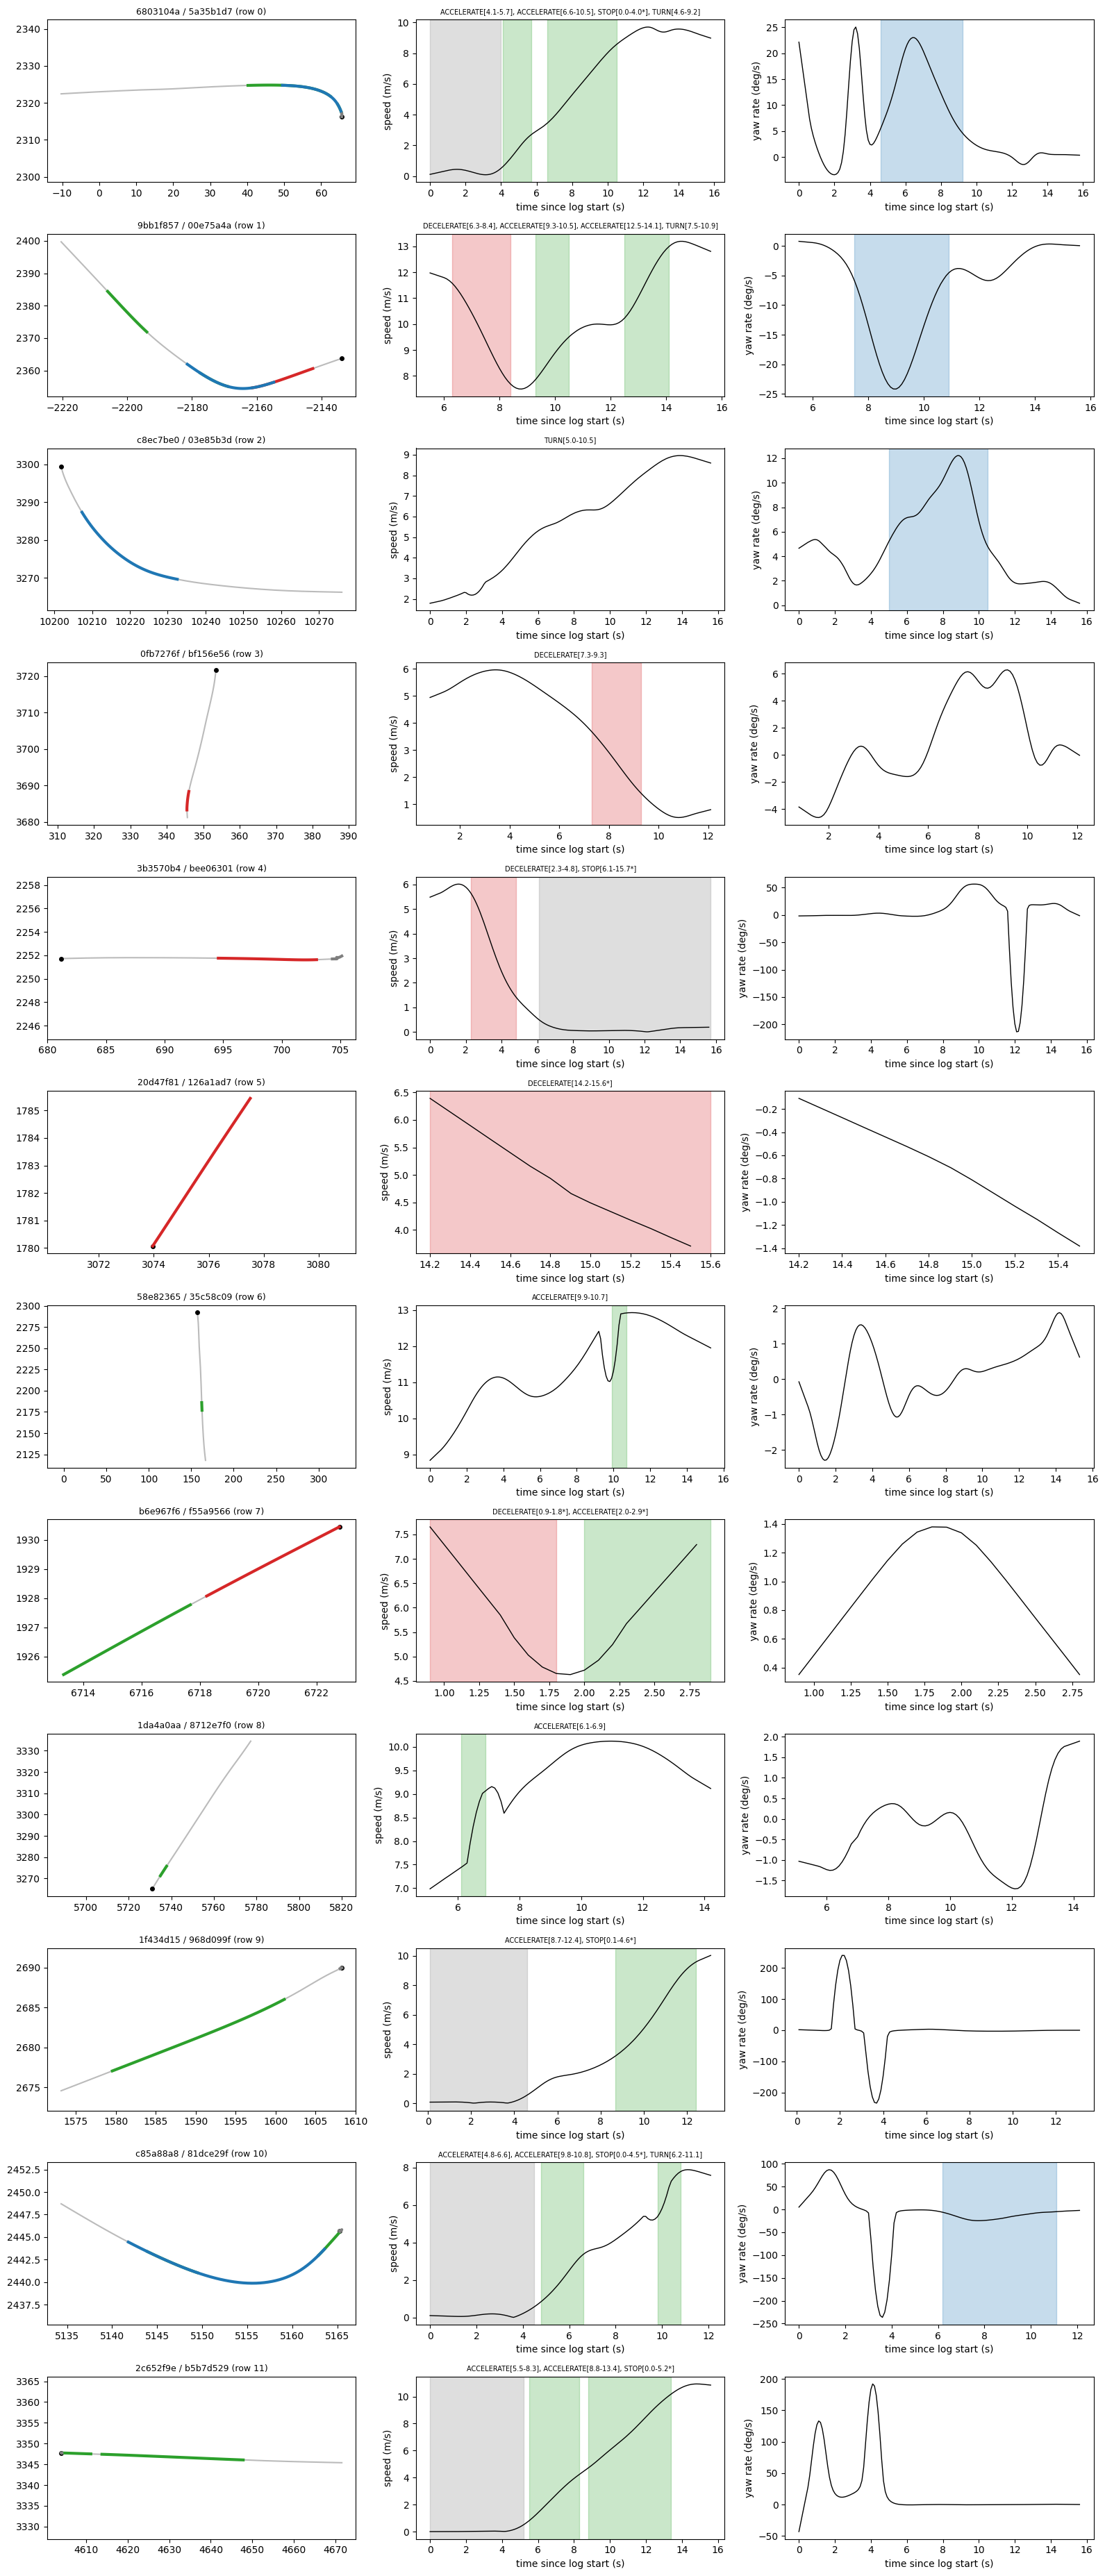

수동 확인용 사건: 26 개 -> /content/tqp_teg_out/val_20261014_113025/manual_event_check.csv


In [10]:
import matplotlib.pyplot as plt

track_events = defaultdict(list)
for e in events:
    track_events[e.track_key].append(e)
rng = np.random.default_rng(SEED)
chosen = []
per_type = max(1, N_TRACKS_TO_PLOT // len(T.EVENT_TYPES))
for typ in T.EVENT_TYPES:
    pool = sorted({e.track_key for e in events if e.type == typ} - set(chosen))
    chosen += [pool[i] for i in rng.permutation(len(pool))[:per_type]]
if chosen:
    fig, axes = plt.subplots(len(chosen), 3, figsize=(16, 3.1 * len(chosen)), squeeze=False)
    for row, key in enumerate(chosen):
        T.plot_track(key, track_events[key], signals[key], axes[row], f"(row {row})")
    fig.tight_layout()
    fig.savefig(OUT / "detector_check.png", dpi=110)
    plt.show()
    row_of = {k: i for i, k in enumerate(chosen)}
    manual = event_df[[(l, t) in row_of for l, t in zip(event_df.log_id, event_df.track_id)]].copy()
    manual.insert(0, "figure_row", [row_of[(l, t)] for l, t in zip(manual.log_id, manual.track_id)])
    manual["verdict"], manual["note"] = "", ""
    manual.sort_values(["figure_row", "start"]).to_csv(OUT / "manual_event_check.csv", index=False)
    print("수동 확인용 사건:", len(manual), "개 ->", OUT / "manual_event_check.csv")
else:
    print("검출된 사건이 없어 시각 검증을 생략합니다.")

## 5. [계층 4] Graph Query Execution 검증

동일한 TQP 32개(4유형 × THEN/WHILE × 4유형)를 두 실행기에 넣습니다.
- **Interval 실행기**: 질의 시점마다 사건 구간 쌍을 비교합니다.
- **Graph 실행기**: TQP를 `(:Event{type})-[:REL]->(:Event{type})` 패턴으로 변환해 사전 계산된 엣지를 조회합니다.

트랙별 판정(POSITIVE/UNCERTAIN/PARTIAL/NEGATIVE)과 반환된 사건 쌍이 모두 같아야 합니다. 이 일치는 같은 판정 규칙을 두 방식으로 구현했다는 소프트웨어 검증이며, Graph의 검색 정확도가 더 높다는 뜻이 아닙니다.

In [11]:
queries = T.all_queries()
t0 = time.perf_counter()
exec_report, _ = T.verify_and_benchmark(events, universe, queries, repeat=LATENCY_REPEAT)
print(f"검증 소요: {time.perf_counter() - t0:.1f}s")
q_df = pd.DataFrame(exec_report["per_query"])[["query", "status_equal", "retrieval_equal", "matches",
                                                "positive_tracks", "uncertain_tracks", "partial_tracks",
                                                "interval_ms", "graph_ms"]]
display(q_df)
print("모든 판정 일치:", exec_report["all_status_equal"], "| 모든 반환 결과 일치:", exec_report["all_retrieval_equal"])
print("그래프 구축(중앙값) ms:", exec_report["graph_build_ms_median"],
      "| 보존 메모리 KiB:", exec_report["graph_retained_memory_kib"])
print("평균 질의 ms  Interval:", exec_report["retrieval_latency_interval_ms_mean"],
      "| Graph:", exec_report["retrieval_latency_graph_ms_mean"],
      "| 손익분기 질의 수:", exec_report["break_even_query_count"])
assert exec_report["all_status_equal"] and exec_report["all_retrieval_equal"], "두 실행기 불일치: per_query mismatches 확인"

검증 소요: 14.3s


,query,status_equal,retrieval_equal,matches,positive_tracks,uncertain_tracks,partial_tracks,interval_ms,graph_ms
0,TURN THEN TURN,True,True,2,2,0,0,0.75768,0.00711
1,TURN THEN DECELERATE,True,True,32,31,0,32,5.17481,0.07356
2,TURN THEN ACCELERATE,True,True,14,13,0,51,6.70733,0.03246
3,TURN THEN STOP,True,True,6,6,0,11,8.32315,0.01538
4,TURN WHILE TURN,True,True,0,0,0,0,0.69639,0.00086
5,TURN WHILE DECELERATE,True,True,23,23,1,35,4.99404,0.05373
6,TURN WHILE ACCELERATE,True,True,90,87,0,49,6.99695,0.20408
7,TURN WHILE STOP,True,True,1,1,4,7,8.61398,0.00297
8,DECELERATE THEN TURN,True,True,32,28,0,34,5.75953,0.07098
9,DECELERATE THEN DECELERATE,True,True,113,100,0,0,9.20612,0.25154


모든 판정 일치: True | 모든 반환 결과 일치: True
그래프 구축(중앙값) ms: 239.271 | 보존 메모리 KiB: 724.6
평균 질의 ms  Interval: 16.66721 | Graph: 0.10129 | 손익분기 질의 수: 15


## 6. [계층 1·2] Temporal Relation Grounding + Temporal Query Plan (Qwen2.5-1.5B-Instruct)

템플릿 문장 72개(THEN 60, WHILE 12)를 TQP JSON으로 변환합니다.
- **어순 일치(congruent)**: "A vehicle slows down before turning." — 먼저 언급된 사건이 먼저 발생
- **어순 불일치(incongruent)**: "A vehicle turns after slowing down." — 먼저 언급된 사건이 나중에 발생
- **동시(simultaneous)**: while / as

TQP에서 `e1`, `e2`는 언급 순서, `args`는 실제 시간 순서입니다. 출력은 JSON 스키마 검증만 거치며 코드로 실행되지 않습니다. 프롬프트의 예시 3개는 평가 문장에 포함되지 않습니다.

In [12]:
diag = N.build_diagnostic_set()
print("진단 문장 수:", len(diag), dict(diag.condition.value_counts()))
LLM_STATUS, llm_info = "not_run", {}
raw_outputs = [None] * len(diag)
if USE_LLM:
    try:
        raw_outputs, llm_info, _ = N.run_llm(diag.sentence.tolist(), LLM_MODEL_ID, batch_size=LLM_BATCH_SIZE)
        LLM_STATUS = "ok"
    except Exception as exc:
        LLM_STATUS = f"failed: {type(exc).__name__}: {exc}"
print("LLM 상태:", LLM_STATUS)
print(json.dumps(llm_info, ensure_ascii=False))

records, pred_queries, pred_plans = [], [], []
for (_, row), text in zip(diag.iterrows(), raw_outputs):
    gold = T.Query(row.gold_first, row.gold_relation, row.gold_second)
    if text is None:
        pred, plan, err = None, None, "LLM not run"
    else:
        pred, plan, err = N.parse_prediction(text)
    pred_queries.append(pred)
    pred_plans.append(plan)
    records.append({**row.to_dict(), "raw_output": text, "pred": str(pred) if pred else None,
                    "parse_error": err, **N.score(gold, pred)})
nl = pd.DataFrame(records)
nl.to_csv(OUT / "llm_tqp_predictions.csv", index=False)

if LLM_STATUS == "ok":
    print("\n[어순 조건별]")
    display(N.summarize(nl, "condition"))
    print("\n[템플릿별]")
    display(N.summarize(nl, "template"))
    wrong = nl[~nl.exact][["sentence", "condition", "gold_first", "gold_relation", "gold_second",
                           "pred", "parse_error", "raw_output"]]
    print(f"\n오답 {len(wrong)}개 (최대 15개 표시)")
    display(wrong.head(15))
else:
    print("LLM이 실행되지 않아 계층 1·2 측정값이 없습니다. 7절은 정답 TQP로만 실행됩니다.")

진단 문장 수: 72 {'congruent': np.int64(36), 'incongruent': np.int64(24), 'simultaneous': np.int64(12)}


config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

... (6 outputs left out)


[템플릿별]


,n,valid_tqp,relation_acc,event_acc,direction_acc(THEN),exact_plan_acc
template,,,,,,
after,12,1.0,1.000,1.0,0.750,0.750
after_fronted,12,1.0,1.000,1.0,0.750,0.750
and_then,12,1.0,1.000,1.0,1.000,1.000
as,4,1.0,1.000,1.0,NaN,1.000
before,12,1.0,0.417,1.0,0.417,0.417
before_fronted,12,1.0,0.333,1.0,0.333,0.333
while,4,1.0,1.000,1.0,NaN,1.000
while_fronted,4,1.0,1.000,1.0,NaN,1.000



오답 21개 (최대 15개 표시)


,sentence,condition,gold_first,gold_relation,gold_second,pred,parse_error,raw_output
0,A vehicle turns before slowing down.,congruent,TURN,THEN,DECELERATE,TURN WHILE DECELERATE,None,"{""events"": {""e1"": ""TURN"", ""e2"": ""DECELERATE""},..."
3,A vehicle slows down before turning.,congruent,DECELERATE,THEN,TURN,DECELERATE WHILE TURN,None,"{""events"": {""e1"": ""DECELERATE"", ""e2"": ""TURN""},..."
6,A vehicle speeds up before turning.,congruent,ACCELERATE,THEN,TURN,ACCELERATE WHILE TURN,None,"{""events"": {""e1"": ""ACCELERATE"", ""e2"": ""TURN""},..."
7,A vehicle speeds up before slowing down.,congruent,ACCELERATE,THEN,DECELERATE,ACCELERATE WHILE DECELERATE,None,"{""events"": {""e1"": ""ACCELERATE"", ""e2"": ""DECELER..."
9,A vehicle stops before turning.,congruent,STOP,THEN,TURN,TURN WHILE STOP,None,"{""events"": {""e1"": ""STOP"", ""e2"": ""TURN""}, ""rela..."
10,A vehicle stops before slowing down.,congruent,STOP,THEN,DECELERATE,STOP WHILE DECELERATE,None,"{""events"": {""e1"": ""STOP"", ""e2"": ""DECELERATE""},..."
11,A vehicle stops before speeding up.,congruent,STOP,THEN,ACCELERATE,STOP WHILE ACCELERATE,None,"{""events"": {""e1"": ""STOP"", ""e2"": ""ACCELERATE""},..."
14,A vehicle turns after stopping.,incongruent,STOP,THEN,TURN,TURN THEN STOP,None,"{""events"": {""e1"": ""STOP"", ""e2"": ""TURN""}, ""rela..."
16,A vehicle slows down after speeding up.,incongruent,ACCELERATE,THEN,DECELERATE,DECELERATE THEN ACCELERATE,None,"{""events"": {""e1"": ""ACCELERATE"", ""e2"": ""DECELER..."
23,A vehicle stops after speeding up.,incongruent,ACCELERATE,THEN,STOP,STOP THEN ACCELERATE,None,"{""events"": {""e1"": ""ACCELERATE"", ""e2"": ""STOP""},..."


## 7. End-to-end: 자연어 → TQP → 그래프 검색

각 문장에 대해 LLM이 만든 TQP로 그래프를 검색한 결과와 정답 TQP로 검색한 결과(트랙 집합)를 비교합니다. 해석 오류가 검색 결과에 어떻게 전파되는지를 보여 줍니다. 정답 검색 결과가 비어 있는 문장은 오답이어도 일치로 집계될 수 있으므로, 결과가 있는 문장 기준 수치를 주 지표로 보십시오.

In [13]:
e2e = []
for (_, row), pred in zip(nl.iterrows(), pred_queries):
    gold = T.Query(row.gold_first, row.gold_relation, row.gold_second)
    gold_tracks = {(m.log_id, m.track_id) for m in gexec.retrieve(gold)}
    pred_tracks = {(m.log_id, m.track_id) for m in gexec.retrieve(pred)} if pred else set()
    union = gold_tracks | pred_tracks
    e2e.append({"sentence": row.sentence, "condition": row.condition, "gold": str(gold),
                "pred": str(pred) if pred else None, "gold_tracks": len(gold_tracks),
                "pred_tracks": len(pred_tracks), "same_track_set": gold_tracks == pred_tracks,
                "jaccard": (len(gold_tracks & pred_tracks) / len(union)) if union else 1.0})
e2e_df = pd.DataFrame(e2e)
e2e_df.to_csv(OUT / "end_to_end.csv", index=False)
if LLM_STATUS == "ok":
    nonempty = e2e_df[e2e_df.gold_tracks > 0]
    print("트랙 집합 일치율 (전체):", round(e2e_df.same_track_set.mean(), 3))
    print(f"트랙 집합 일치율 (정답 결과가 비어 있지 않은 문장 {len(nonempty)}개):",
          round(nonempty.same_track_set.mean(), 3) if len(nonempty) else "해당 없음")
    display(e2e_df.groupby("condition")[["same_track_set", "jaccard"]].mean().round(3))
print("\n정답 TQP별 검색된 트랙 수")
display(e2e_df.groupby("gold").gold_tracks.first().sort_values(ascending=False).to_frame())

트랙 집합 일치율 (전체): 0.708
트랙 집합 일치율 (정답 결과가 비어 있지 않은 문장 72개): 0.708


,same_track_set,jaccard
condition,,
congruent,0.722,0.728
incongruent,0.542,0.562
simultaneous,1.000,1.000



정답 TQP별 검색된 트랙 수


,gold_tracks
gold,
STOP THEN ACCELERATE,242
DECELERATE THEN STOP,207
ACCELERATE THEN DECELERATE,148
DECELERATE THEN ACCELERATE,108
TURN WHILE ACCELERATE,87
ACCELERATE WHILE TURN,87
STOP THEN TURN,40
TURN THEN DECELERATE,31
DECELERATE THEN TURN,28


① 입력 문장           : A vehicle turns after slowing down.
② LLM 원출력          : {"events": {"e1": "DECELERATE", "e2": "TURN"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}}
③ Temporal Query Plan : {"events": {"e1": "DECELERATE", "e2": "TURN"}, "relation": {"op": "THEN", "args": ["e1", "e2"]}}
④ 시간 관계 해석       : DECELERATE THEN TURN | 정답: 정답
⑤ 그래프 질의 패턴     : (:Event {type:'DECELERATE'})-[:THEN]->(:Event {type:'TURN'})
⑥ 검색 결과            : 사건 쌍 32개, 트랙 28개


,log_id,track_id,first_type,first_start,first_end,second_type,second_start,second_end
0,20d47f81-46e8-3adf-a0ca-564fbb5c599d,54be6630-0405-4a93-9015-c0de6fa7cb48,DECELERATE,6.1,6.9,TURN,11.9,15.0
1,25e5c600-36fe-3245-9cc0-40ef91620c22,58b1ffd9-2e5f-4531-b61b-d0aa42ac1869,DECELERATE,3.0,4.4,TURN,7.4,13.1
2,2c652f9e-8db8-3572-aa49-fae1344a875b,61fc38cf-43c5-45e6-aaea-95f33cec7d67,DECELERATE,1.6,5.4,TURN,7.0,12.0
3,335aabef-269e-3211-a99d-2c3a3a8f8475,5f0e23c2-13a9-4930-9567-0bdab1e8c95b,DECELERATE,1.5,4.4,TURN,4.3,9.7
4,3b3570b4-7b0b-3268-a571-b0889dbf40b6,fc1f6c44-3cf4-455b-934a-cd99fdaaffd7,DECELERATE,8.4,10.6,TURN,11.0,15.6
5,3de5b5d6-68c4-3c95-84ed-be7c83d829f8,148e0484-c728-406f-a58b-29024daef4be,DECELERATE,4.1,8.0,TURN,8.9,13.2
6,3de5b5d6-68c4-3c95-84ed-be7c83d829f8,8521bfe8-2550-4557-ba1c-70c2add7238d,DECELERATE,7.0,9.9,TURN,10.2,15.4
7,3de5b5d6-68c4-3c95-84ed-be7c83d829f8,c0447916-56c3-464e-a010-168531984410,DECELERATE,2.0,3.7,TURN,4.9,8.7
8,3de5b5d6-68c4-3c95-84ed-be7c83d829f8,c4e428e6-be5d-4cea-a980-b2aa50f0a560,DECELERATE,3.9,6.0,TURN,8.0,14.1
9,42f92807-0c5e-3397-bd45-9d5303b4db2a,07ec928e-3ca4-4e65-8d85-58cf88dfec98,DECELERATE,4.8,6.4,TURN,7.9,12.2


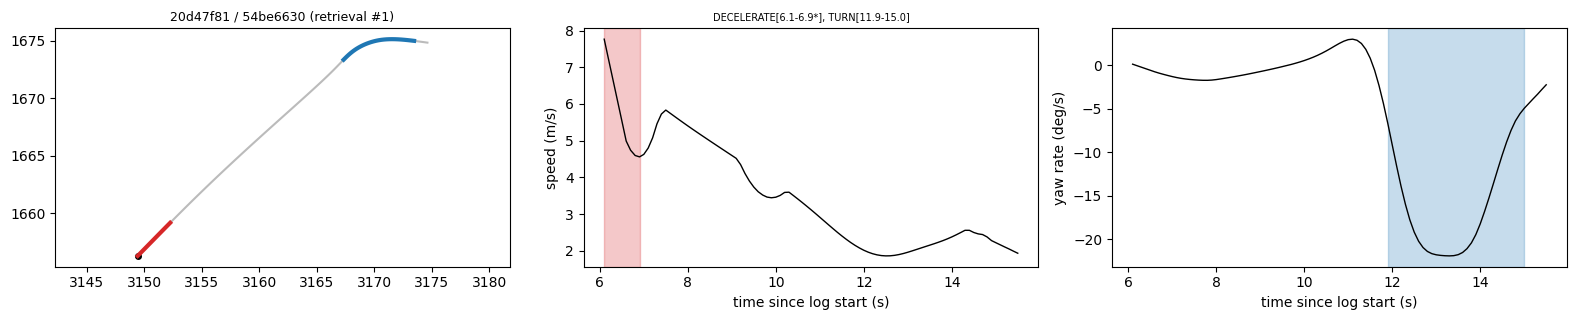

In [14]:
# 한 문장의 전 과정 추적
EXAMPLE = "A vehicle turns after slowing down."
i = int(nl.index[nl.sentence == EXAMPLE][0])
use_llm = LLM_STATUS == "ok" and pred_queries[i] is not None
q = pred_queries[i] if use_llm else T.Query(nl.gold_first[i], nl.gold_relation[i], nl.gold_second[i])
plan = pred_plans[i] if use_llm else json.loads(nl.gold_tqp[i])
print("① 입력 문장           :", EXAMPLE)
print("② LLM 원출력          :", (raw_outputs[i] or "(LLM 미실행: 정답 TQP 사용)").strip())
print("③ Temporal Query Plan :", json.dumps(plan))
print("④ 시간 관계 해석       :", q, "| 정답:", "정답" if nl.exact[i] else "오답")
print("⑤ 그래프 질의 패턴     :", gexec.pattern(q))
matches = gexec.retrieve(q)
print(f"⑥ 검색 결과            : 사건 쌍 {len(matches)}개, 트랙 {len({(m.log_id, m.track_id) for m in matches})}개")
if matches:
    display(pd.DataFrame([asdict(m) for m in matches])[["log_id", "track_id", "first_type", "first_start",
                                                        "first_end", "second_type", "second_start", "second_end"]]
            .round(2).head(10))
    key = (matches[0].log_id, matches[0].track_id)
    fig, axes = plt.subplots(1, 3, figsize=(16, 3.3), squeeze=False)
    T.plot_track(key, track_events[key], signals[key], axes[0], "(retrieval #1)")
    fig.tight_layout(); fig.savefig(OUT / "example_retrieval.png", dpi=110); plt.show()

## 8. 4계층 작동 확인 요약 및 저장

In [15]:
def acc(df, col):
    v = df[col].dropna().astype(float)
    return round(float(v.mean()), 3) if len(v) else None

llm_ok = LLM_STATUS == "ok"
nonempty_e2e = e2e_df[e2e_df.gold_tracks > 0]
then_rows = nl[nl.gold_relation == "THEN"]
summary = pd.DataFrame([
    {"계층": "Temporal Relation Grounding", "작동": llm_ok,
     "근거": (f"관계 정확도 {acc(nl, 'relation_correct')}, THEN 방향 정확도: 어순 일치 "
              f"{acc(then_rows[then_rows.condition == 'congruent'], 'direction_correct')} / 불일치 "
              f"{acc(then_rows[then_rows.condition == 'incongruent'], 'direction_correct')}") if llm_ok else LLM_STATUS},
    {"계층": "Temporal Query Plan", "작동": llm_ok and bool(nl.valid.any()),
     "근거": f"스키마 유효 TQP {acc(nl, 'valid')}, 계획 완전 일치 {acc(nl, 'exact')}" if llm_ok else LLM_STATUS},
    {"계층": "Temporal Event Graph", "작동": gsum["relation_edges"] > 0,
     "근거": (f"트랙 {gsum['track_nodes']}, 사건 {gsum['event_nodes']}, 관계 엣지 {gsum['relation_edges']} "
              f"{gsum['relation_edges_by_type']}")},
    {"계층": "Graph Query Execution",
     "작동": exec_report["all_status_equal"] and exec_report["all_retrieval_equal"],
     "근거": (f"32개 TQP 판정·결과 Interval과 일치, 평균 질의 Interval "
              f"{exec_report['retrieval_latency_interval_ms_mean']} ms / Graph "
              f"{exec_report['retrieval_latency_graph_ms_mean']} ms, 구축 {exec_report['graph_build_ms_median']} ms, "
              f"손익분기 {exec_report['break_even_query_count']}회")},
    {"계층": "End-to-end", "작동": llm_ok,
     "근거": (f"LLM TQP와 정답 TQP의 검색 트랙 집합 일치율: 정답 결과가 있는 문장 {len(nonempty_e2e)}개 기준 "
              f"{acc(nonempty_e2e, 'same_track_set')} (빈 결과 포함 전체 {acc(e2e_df, 'same_track_set')})")
             if llm_ok else "LLM 미실행"},
])
pd.set_option("display.max_colwidth", 200)
display(summary)

final = {"created": STAMP, "engine_version": T.VERSION, "data_source": "official AV2 Sensor annotations + ego pose",
         "acquisition": acquisition, "logs_loaded": int(len(folders)), "moving_tracks": len(universe),
         "events": len(events), "graph": gsum, "graph_query_execution": exec_report,
         "llm_status": LLM_STATUS, "llm_info": llm_info,
         "grounding_by_condition": N.summarize(nl, "condition").reset_index().to_dict("records") if llm_ok else None,
         "end_to_end_track_set_agreement_all": acc(e2e_df, "same_track_set") if llm_ok else None,
         "end_to_end_track_set_agreement_nonempty_gold": acc(nonempty_e2e, "same_track_set") if llm_ok else None,
         "layer_summary": summary.to_dict("records")}
(OUT / "report.json").write_text(json.dumps(final, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
summary.to_csv(OUT / "layer_summary.csv", index=False)
archive = shutil.make_archive(str(OUT), "zip", root_dir=OUT)
if DRIVE_MOUNTED:
    dest = Path(DRIVE_ROOT) / RESULTS_DIR_NAME / OUT.name
    shutil.copytree(OUT, dest)
    print("Drive 저장:", dest)
print("결과 ZIP:", archive)

,계층,작동,근거
0,Temporal Relation Grounding,True,"관계 정확도 0.792, THEN 방향 정확도: 어순 일치 0.722 / 불일치 0.542"
1,Temporal Query Plan,True,"스키마 유효 TQP 1.0, 계획 완전 일치 0.708"
2,Temporal Event Graph,True,"트랙 3531, 사건 3269, 관계 엣지 1527 {'THEN': 1299, 'WHILE': 228}"
3,Graph Query Execution,True,"32개 TQP 판정·결과 Interval과 일치, 평균 질의 Interval 16.66721 ms / Graph 0.10129 ms, 구축 239.271 ms, 손익분기 15회"
4,End-to-end,True,LLM TQP와 정답 TQP의 검색 트랙 집합 일치율: 정답 결과가 있는 문장 72개 기준 0.708 (빈 결과 포함 전체 0.708)


Drive 저장: /content/drive/MyDrive/AV2_TQP_TEG_Results/val_20261014_113025
결과 ZIP: /content/tqp_teg_out/val_20261014_113025.zip


## 9. 결과 해석 시 유의 사항

- **Graph Query Execution의 일치**는 같은 판정식을 두 방식으로 구현했다는 검증입니다. 정확도 우위의 근거가 아닙니다.
- **질의 시간 차이**는 경계 잘림 판정을 포함한 관계 계산을 그래프가 미리 해 두기 때문에 생깁니다. 반드시 구축 시간·메모리·손익분기 질의 수와 함께 보고하십시오.
- **LLM 결과**는 템플릿 문장 72개, 예시 3개를 포함한 프롬프트, 탐욕적 디코딩 조건의 측정값입니다. 일반화 성능이 아니며, H1 검증에는 같은 조건의 직접 Python 생성(B2) 비교가 추가로 필요합니다.
- **사건 검출기**는 규칙 기반 파일럿입니다. `manual_event_check.csv`로 측정한 정밀도 없이 검색 결과를 "실제 주행 장면"이라고 단정하지 마십시오.
- **val split**은 개발용입니다. 임계값을 조정했다면 최종 평가는 다른 split에서 수행하십시오.
- 실제로 실행해 얻은 수치만 보고하고, 사용한 AI 도구와 지원 범위는 Appendix AI Usage에 기재하십시오.